# Degree correlations and assortativity

**Question.** In the Bitcoin OTC trust network, do well-connected users link to other well-connected users, or mainly to users with few links? And is that more than the degree distribution alone would force?

**Before running this notebook**, run from the repository root:

`python scripts/degree_correlations.py`

The script writes its results to `outputs/correlations/`; this notebook reads and interprets them.

## Definitions

- **Assortativity coefficient `r`.** The Pearson correlation between the degrees at the two ends of a link. `r > 0`: high-degree users link to high-degree users (assortative). `r < 0`: high-degree users link to low-degree users (disassortative). `r ≈ 0`: no degree correlation.
- **Average neighbour degree `k_nn(k)`.** The mean degree of the neighbours of users with degree `k`. A decreasing curve indicates disassortative mixing; a flat curve at `<k²>/<k>` indicates no degree correlations. The scaling form is `k_nn(k) ∝ k^μ`.
- **Degree-preserving rewiring (null model).** Edge swaps that keep every user's degree fixed while randomising who is linked to whom. The same eight seeds and swap budget as `outputs/flagship` are used, so any difference from the rewires reflects the wiring and not the degrees.
- **Structural cutoff `k_s = √(<k>·N)`.** In a simple graph, users with degree above `k_s` cannot have enough distinct partners of similar degree, which forces negative correlations even without any preference for hub-to-low-degree links. The observed `r` is therefore compared with the rewired `r`, not with 0.

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'outputs' / 'correlations'
if not (OUT / 'correlation_summary.csv').exists():
    raise FileNotFoundError('Run  python scripts/degree_correlations.py  from the repository root first.')

summary = pd.read_csv(OUT / 'correlation_summary.csv').iloc[0]
directed = pd.read_csv(OUT / 'directed_assortativity.csv')
knn = pd.read_csv(OUT / 'knn_by_degree.csv')
rewired = pd.read_csv(OUT / 'rewired_assortativity.csv')
metadata = json.loads((OUT / 'metadata.json').read_text())

## Result 1: the undirected network

In [2]:
display(summary.to_frame('value').round(4))
print(f"Users: {int(summary.nodes)}, links: {int(summary.edges)}, "
      f"largest degree k_max = {int(summary.max_degree)}, structural cutoff k_s = {summary.structural_cutoff:.0f}")

,value
nodes,5881
edges,18591
mean_degree,6.322394
max_degree,788
structural_cutoff,192.826347
r_observed,-0.144884
r_rewired_mean,-0.114437
r_rewired_std,0.001939
r_rewired_min,-0.118427
r_rewired_max,-0.112233


Users: 5881, links: 18591, largest degree k_max = 788, structural cutoff k_s = 193


In [3]:
obs, mean = summary.r_observed, summary.r_rewired_mean
lo, hi = summary.r_rewired_min, summary.r_rewired_max

print(f"Observed r = {obs:+.4f}.  Degree-preserving rewires give r = {mean:+.4f} "
      f"(range {lo:+.4f} to {hi:+.4f}).")
if obs < lo:
    print('-> The real network is MORE disassortative than its degrees alone force: '
          'high-degree users link to low-degree users more than chance allows.')
elif obs > hi:
    print('-> The real network is MORE assortative (or less disassortative) than its degrees alone force.')
else:
    print('-> The observed r lies inside the rewired range: no evidence that the wiring differs '
          'from what the degrees alone produce.')

if summary.max_degree > summary.structural_cutoff:
    print(f"-> k_max ({int(summary.max_degree)}) is above the structural cutoff ({summary.structural_cutoff:.0f}), "
          f"so some negative r is forced by the degrees themselves. This is why the rewired r is {mean:+.3f} and not 0.")
else:
    print('-> k_max is below the structural cutoff, so degrees alone do not force negative correlations.')

Observed r = -0.1449.  Degree-preserving rewires give r = -0.1144 (range -0.1184 to -0.1122).
-> The real network is MORE disassortative than its degrees alone force: high-degree users link to low-degree users more than chance allows.
-> k_max (788) is above the structural cutoff (193), so some negative r is forced by the degrees themselves. This is why the rewired r is -0.114 and not 0.


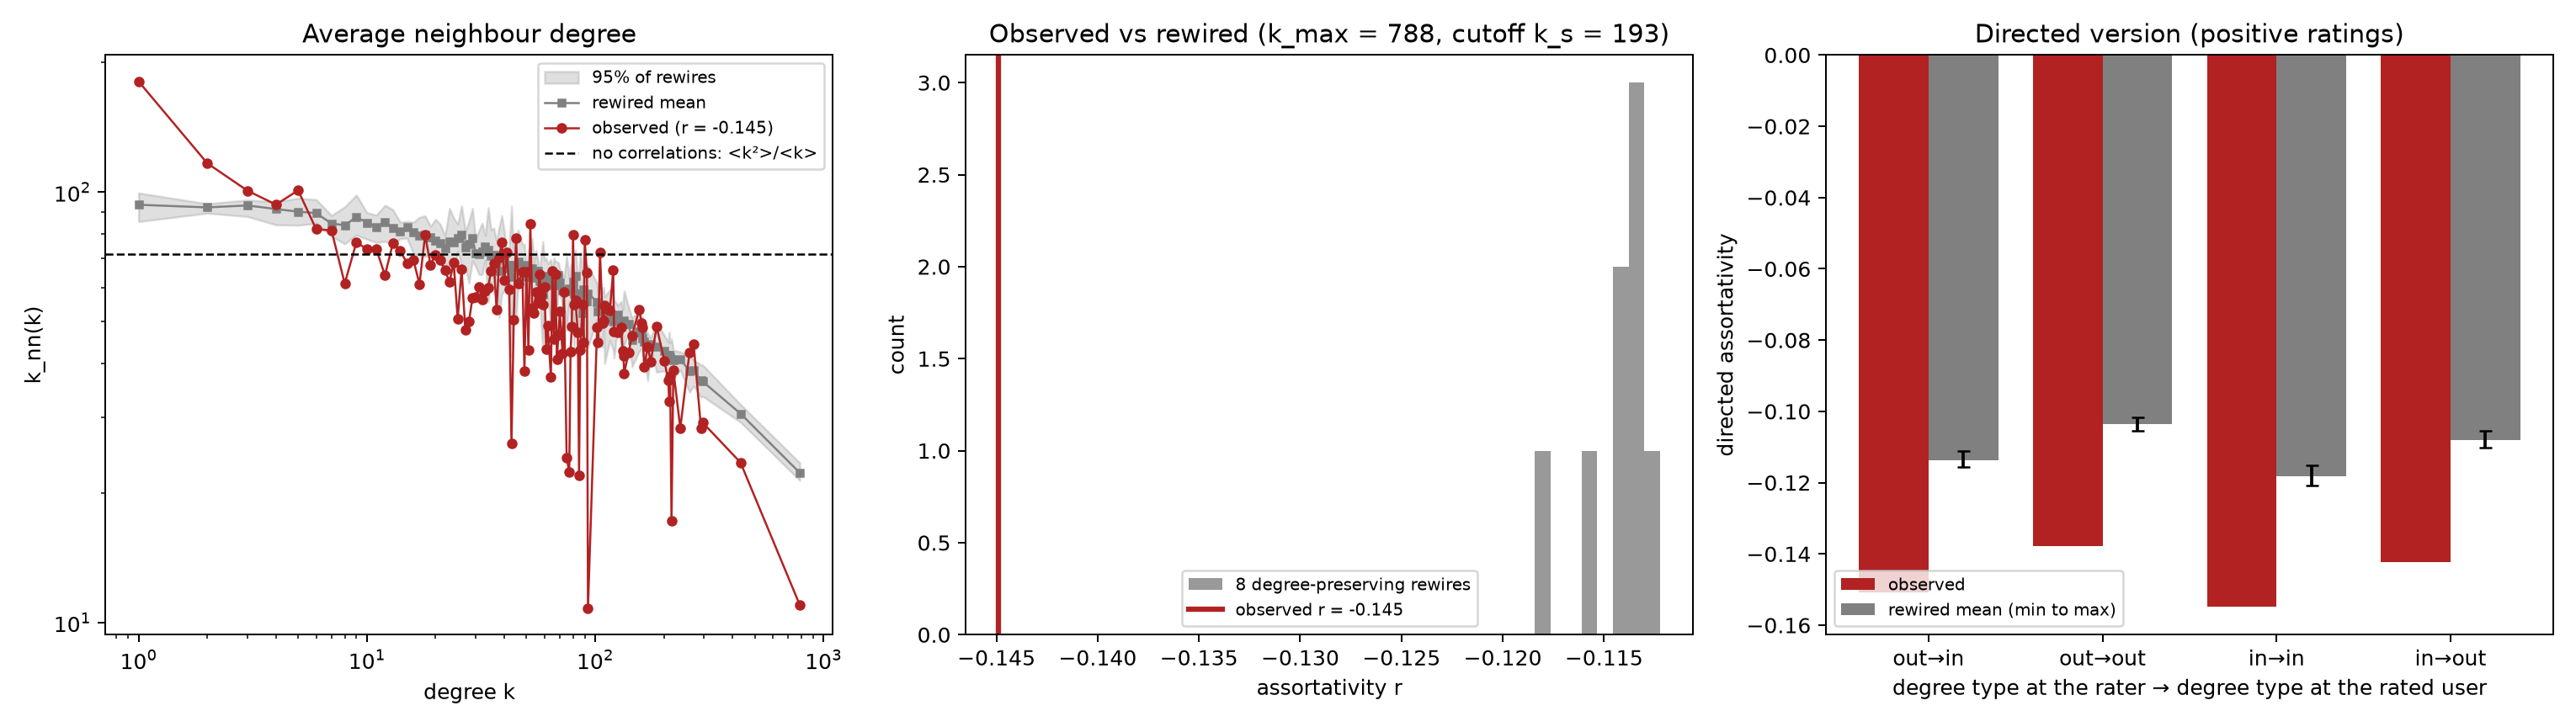

In [4]:
display(Image(filename=str(OUT / 'degree_correlations.png')))

In [5]:
print('mu (k_nn ~ k^mu): observed =', round(summary.mu_observed, 3) if pd.notna(summary.mu_observed) else 'not reported',
      '| rewired mean =', round(summary.mu_rewired_mean, 3) if pd.notna(summary.mu_rewired_mean) else 'not reported')
display(knn.head(10).round(2))

mu (k_nn ~ k^mu): observed = -0.225 | rewired mean = -0.104


,degree,users_with_degree,knn_observed,knn_rewired_mean,knn_rewired_p2_5,knn_rewired_p97_5
0,1,2226,180.71,93.42,85.37,99.50
1,2,971,116.63,92.12,89.30,93.93
2,3,552,100.73,93.09,87.71,95.85
3,4,337,93.50,91.31,83.90,94.86
4,5,219,100.92,90.06,83.72,96.79
5,6,179,81.95,89.31,84.59,96.01
6,7,133,81.47,84.54,78.93,88.22
7,8,116,61.31,83.71,75.81,92.42
8,9,86,76.47,87.51,79.48,98.43
9,10,93,73.67,84.90,77.70,89.59


## Result 2: the directed version

Ratings have a direction (rater → rated), so degree mixing has four versions. Each label names the degree type at the **rater** and at the **rated user**:

- `out→in`: do users who rate *many* others rate users who *receive many* ratings?
- `out→out`: do heavy raters rate other heavy raters?
- `in→in`: do heavily rated users get rated by other heavily rated users?
- `in→out`: do heavily rated users rate users who rate a lot?

In [6]:
display(directed.round(4))

,type,observed,rewired_mean,rewired_std,rewired_min,rewired_max,z_score,outside_rewired_range
0,out_in,-0.1508,-0.1137,0.0015,-0.1157,-0.1111,-24.3985,True
1,out_out,-0.1378,-0.1037,0.0012,-0.1054,-0.1017,-27.8392,True
2,in_in,-0.1549,-0.1182,0.0019,-0.1208,-0.1152,-19.4291,True
3,in_out,-0.1423,-0.1080,0.0015,-0.1101,-0.1055,-22.6035,True


For the directed null, `directed_edge_swap` keeps each user's in-degree **and** out-degree. A coefficient whose observed value is outside the rewired min–max (`outside_rewired_range` is `True`) is the one that reflects real wiring preferences.

## Findings

1. **The positive trust network is disassortative.** The observed assortativity is `r = -0.145`: high-degree users tend to be linked to users with few links.
2. **Most of this is forced by the degree distribution.** The largest user has `k_max = 788` links, about four times the structural cutoff `k_s ≈ 193`. Degree-preserving rewires, which keep every degree, already give `r ≈ -0.114` (range `-0.118` to `-0.112`). The additional `≈ -0.03` is what the actual wiring contributes.
3. **The extra disassortativity is small but systematic.** The observed value lies outside all eight rewires, and each of the four directed versions (`out→in`, `out→out`, `in→in`, `in→out`) lies about `0.034`–`0.037` below its rewired mean.
4. **Where it comes from.** Users with a single link (2,226 users, about 38%) are attached to neighbours with 181 links on average, against 93 under rewiring. Users with 2–3 links are also above the rewired band, while most users with 6–10 links lie below it. The fitted exponent of `k_nn(k) ∝ k^μ` is `μ = -0.225` for the network and `-0.104` for the rewires. In the left panel the neighbours of the largest hubs also have lower degree than under rewiring.

This is consistent with ratings concentrating on a few well-connected users, as found in the temporal analysis, but a degree-mixing measure cannot identify the mechanism that produced it.

## Limitations

- **z-scores from eight rewires are inflated.** The rewired values are very close together, so the standard deviation is tiny and `z` can be very large. The plain difference `observed − rewired mean` and whether the observed value lies outside the rewired range are more reliable summaries.
- **Rewiring changes more than degree mixing.** It also destroys clustering, community structure and reciprocal pairs, so a difference from the null reflects degree mixing in the presence of those features, not degree mixing alone.
- **Positive ratings only.** Negative ratings (about 10%) are excluded, as in the rest of the project, so this describes the trust network and not the whole rating network.
- **`μ` is reported only where the data support a fit** (at least six degrees held by five or more users, spanning a factor of five); otherwise it is `NaN`.
- **Sparse high-degree region.** Above roughly 40 links each degree is held by only a few users, so single points of the `k_nn(k)` curve there are noisy; the trend is more informative than individual values.

## Outputs and reproducibility

- Files: `outputs/correlations/degree_correlations.png`, `correlation_summary.csv`, `directed_assortativity.csv`, `knn_by_degree.csv`, `rewired_assortativity.csv` and `metadata.json`.
- `scripts/degree_correlations.py` reuses `load_graphs()` and the eight seeds of the other analyses, and checks the source file's SHA-256 before running.